In [1]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import binned_statistic, gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# --- STYLE CONFIGURATION ---
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False, 
        'figure.frameon': True,
        'axes.linewidth': 2., 
        "axes.titlesize" : 20, 
        "axes.labelsize" : 20,
        "legend.fontsize" : 12, 
        'legend.fancybox': True, 
        'lines.linewidth': 2.5,
        'xtick.direction': 'in', 
        'ytick.direction': 'in',
        'xtick.top': True, 
        'ytick.right': True,
        'xtick.labelsize': 18, 
        'ytick.labelsize': 18
    }
    return font, rcnew

# Apply interactive backend and style
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [2]:
# ==============================================================================
# CELL 1: MULTI-MODEL DATA LOADING & PRE-PROCESSING
# ==============================================================================
# 1. Define a dictionary with your models. 
# Easily add more models here as you download them!
DATA_FILES = {
    'Fiducial': '/home/vroberto/FakeSpectra_DLAs/data/fiducial_AllHalos_DLAMode_FullMap_15.pkl',
    'LH_0':     '/home/vroberto/FakeSpectra_DLAs/data/LH_0_AllHalos_DLAMode_FullMap_15.pkl',
    'LH_1':     '/home/vroberto/FakeSpectra_DLAs/data/LH_1_AllHalos_DLAMode_FullMap_15.pkl'
}

HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# Dictionary to store the cleaned DataFrames
dfs_clean = {}
unique_radii = None

print("Loading Multi-Model Data...")
for model_name, file_path in DATA_FILES.items():
    if not os.path.exists(file_path):
        print(f" [!] Warning: {file_path} not found. Skipping {model_name}.")
        continue
        
    print(f" -> Processing {model_name}...")
    df = pd.read_pickle(file_path)
    df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
    
    # Clean data
    df_c = df.dropna(subset=['halo_mass_msun', 'eq_width', 'log_n_hi']).copy()
    df_c['r_mult_round'] = df_c['r_multiplier'].round(2)
    dfs_clean[model_name] = df_c
    
    # Extract unique radii (assuming all models share the same geometry)
    if unique_radii is None:
        unique_radii = np.sort(df_c['r_mult_round'].unique())

n_panels = len(unique_radii)
n_models = len(dfs_clean)

print("-" * 40)
print(f"Successfully loaded {n_models} models.")
print(f"Impact parameters detected: {unique_radii}")

Loading Multi-Model Data...
 -> Processing Fiducial...
 -> Processing LH_0...
 -> Processing LH_1...
----------------------------------------
Successfully loaded 3 models.
Impact parameters detected: [0.   0.01 0.02 0.03 0.05 0.08 0.12 0.17 0.26 0.39 0.59 0.88 1.33 2.
 3.  ]


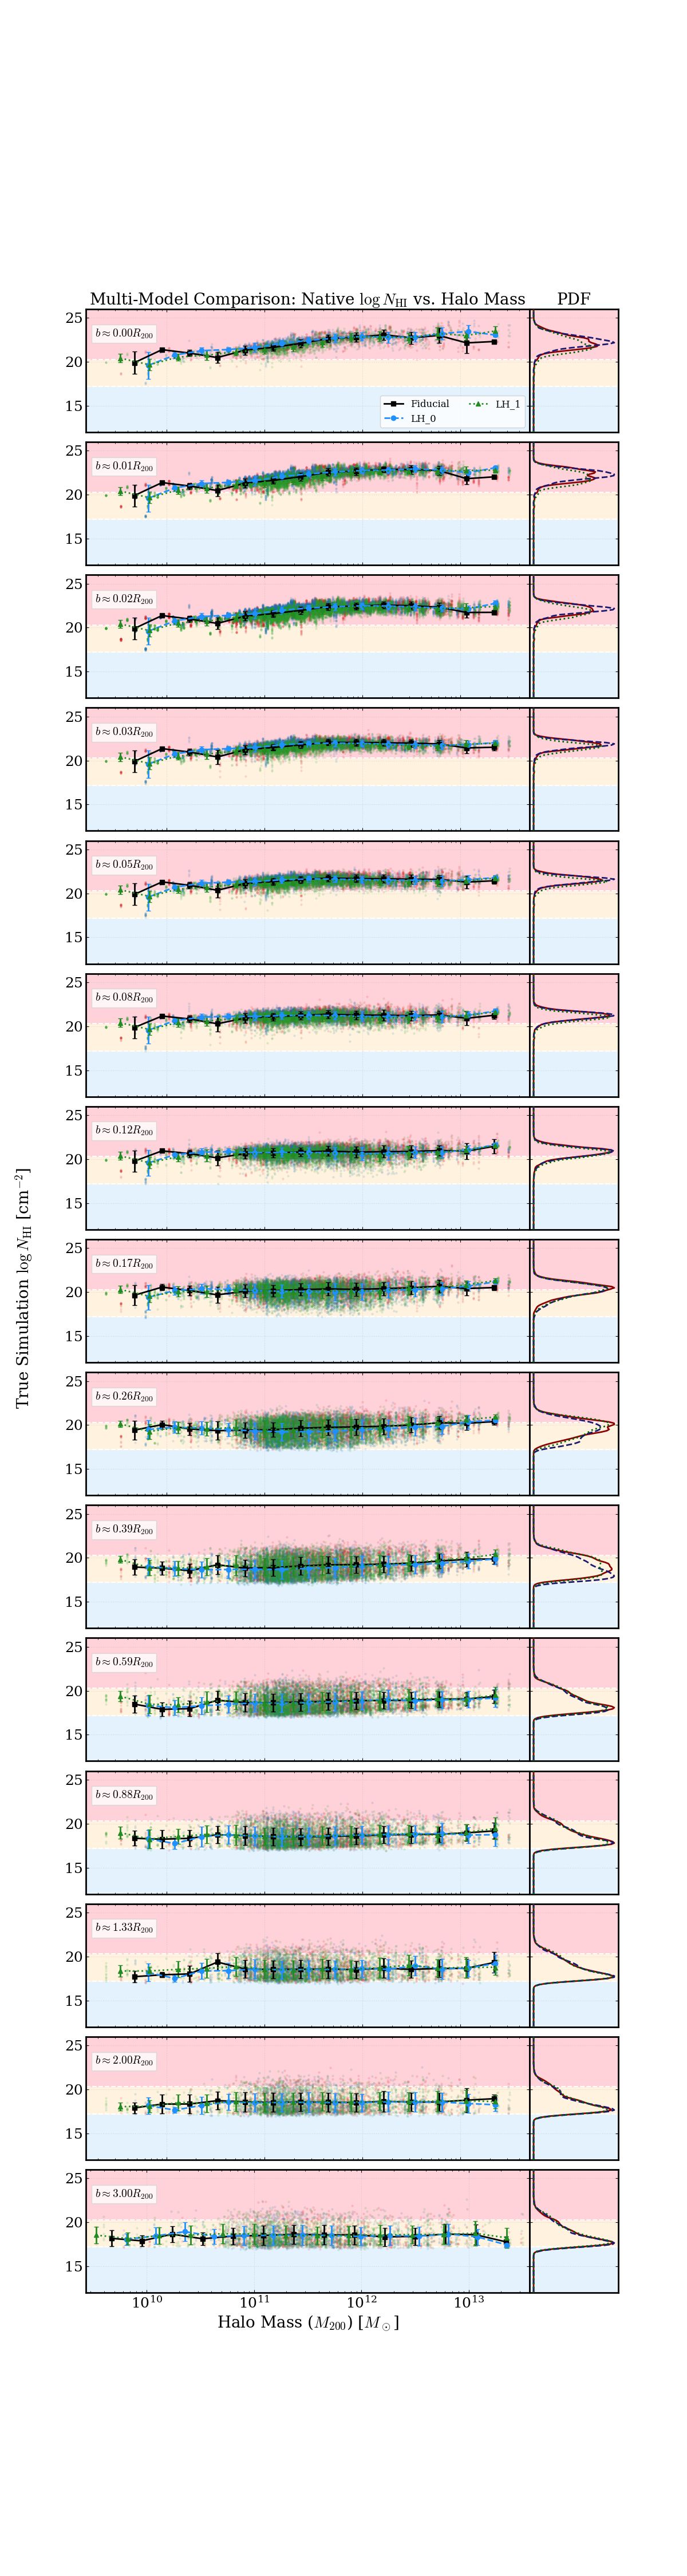

In [3]:
# ==============================================================================
# CELL 2: MULTI-MODEL COMPARISON - NATIVE COLUMN DENSITY (SCATTER & PDF)
# ==============================================================================
import matplotlib.patches as patches
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

fig_nhi, axes_nhi = plt.subplots(n_panels, 2, figsize=(12, 3 * n_panels), sharey=True, 
                                 gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.0, 'hspace': 0.08})
if n_panels == 1: axes_nhi = np.array([axes_nhi])

# Background region colors
c_forest = '#E3F2FD'  # Soft Blue
c_lls    = '#FFF3E0'  # Soft Orange
c_dla    = '#FFD1D8'  # Slightly darker Soft Red/Pink

# Style mapping for models (Expandable for LH_1, LH_2, etc.)
# Index 0 (Fiducial): Black mean, Dark Red PDF, Solid line
# Index 1 (LH_0): DodgerBlue mean, MidnightBlue PDF, Dashed line
colors_scat = ['tab:red', 'tab:blue', 'tab:green']
colors_mean = ['black', 'dodgerblue', 'forestgreen']
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen']
line_styles = ['-', '--', ':']
markers     = ['s', 'o', '^']

for i, b_val in enumerate(unique_radii):
    ax_main, ax_hist = axes_nhi[i, 0], axes_nhi[i, 1]
    
    # 1. Background Regions
    for ax in [ax_main, ax_hist]:
        ax.axhspan(12.0, 17.2, color=c_forest, zorder=0)
        ax.axhspan(17.2, 20.3, color=c_lls, zorder=0)
        ax.axhspan(20.3, 26.0, color=c_dla, zorder=0)
        ax.axhline(17.2, color='white', ls='--', lw=1.5, zorder=0)
        ax.axhline(20.3, color='white', ls='--', lw=1.5, zorder=0)
        ax.grid(True, ls=':', alpha=0.4)

    # 2. Iterate through loaded models to overlay data
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_s = colors_scat[m_idx % len(colors_scat)]
        c_m = colors_mean[m_idx % len(colors_mean)]
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        mkr = markers[m_idx % len(markers)]
        
        df_b = df_model[df_model['r_mult_round'] == b_val]
        df_valid = df_b[(df_b['log_n_hi'] > 1.0) & (df_b['halo_mass_msun'] > 0.0)] 
        
        # Raw Scatter (Very low alpha)
        ax_main.scatter(df_b['halo_mass_msun'], df_b['log_n_hi'], 
                        s=5, alpha=0.1, color=c_s, zorder=1)
        
        if len(df_valid) > 0:
            # Binned Statistics
            bins = np.logspace(np.log10(df_valid['halo_mass_msun'].min()), np.log10(df_valid['halo_mass_msun'].max()), 15)
            means, edges, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'mean', bins=bins)
            stds, _, _ = binned_statistic(df_valid['halo_mass_msun'], df_valid['log_n_hi'], 'std', bins=bins)
            centers = np.sqrt(edges[:-1] * edges[1:])
            
            # Mean line overlay
            ax_main.errorbar(centers, means, yerr=stds, fmt=f'{mkr}{ls}', color=c_m, 
                             markersize=6, capsize=3, lw=2, zorder=5)
            
            # Marginal Distribution (PDF) - No fill, just lines for clean comparison
            if len(df_valid) > 1:
                kde = gaussian_kde(df_valid['log_n_hi'])
                y_grid = np.linspace(12.0, 26.0, 100)
                ax_hist.plot(kde(y_grid), y_grid, color=c_p, lw=2, ls=ls, zorder=3)

    # 3. Aesthetics
    ax_hist.set_xticks([])
    ax_main.set_xscale('log')
    if i < n_panels - 1: 
        ax_main.tick_params(labelbottom=False)
    
    ax_main.text(0.02, 0.85, rf"$b \approx {b_val:.2f} R_{{200}}$", 
                 transform=ax_main.transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgray'), va='top')
    
    if i == 0:
        ax_main.set_title(r"Multi-Model Comparison: Native $\log N_{\rm HI}$ vs. Halo Mass")
        ax_hist.set_title("PDF")
        
        # Build Legend for Models
        custom_lines = [Line2D([0], [0], color=colors_mean[m_idx % len(colors_mean)], 
                               lw=2, ls=line_styles[m_idx % len(line_styles)], 
                               marker=markers[m_idx % len(markers)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        ax_main.legend(handles=custom_lines, loc='lower right', ncol=2, frameon=True)

# Global Axis Labels
axes_nhi[-1, 0].set_xlabel(r"Halo Mass ($M_{200}$) [$M_\odot$]")
fig_nhi.text(0.02, 0.5, r"True Simulation $\log N_{\rm HI}$ [cm$^{-2}$]", va='center', rotation='vertical', fontsize=20)

first_df = list(dfs_clean.values())[0]
axes_nhi[-1, 0].set_xlim(first_df['halo_mass_msun'].min()*0.8, first_df['halo_mass_msun'].max()*1.2)
axes_nhi[-1, 0].set_ylim(12.0, 26.0)

plt.show()

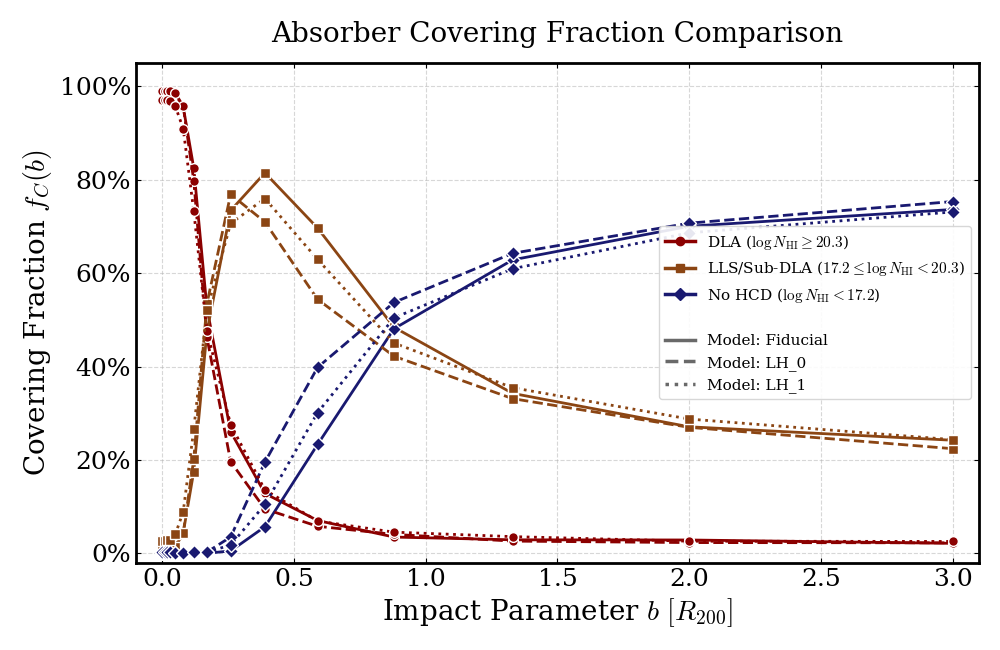

In [4]:
# ==============================================================================
# CELL 3: MULTI-MODEL COVERING FRACTION vs IMPACT PARAMETER (SINGLE PLOT)
# ==============================================================================
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

fig_cov, ax_cov = plt.subplots(figsize=(10, 6.5))

# Define fixed aesthetics for Absorber Categories
cat_styles = {
    'DLA':   {'color': 'darkred',      'marker': 'o', 'label': r'DLA ($\log N_{\mathrm{HI}} \geq 20.3$)'},
    'LLS':   {'color': 'saddlebrown',  'marker': 's', 'label': r'LLS/Sub-DLA ($17.2 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'NoHCD': {'color': 'midnightblue', 'marker': 'D', 'label': r'No HCD ($\log N_{\mathrm{HI}} < 17.2$)'}
}

# Define line styles for Models (Fiducial = Solid, LH_0 = Dashed, etc.)
mod_ls = ['-', '--', ':', '-.']

# Iterate over models to overlay curves
for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
    ls = mod_ls[m_idx % len(mod_ls)]
    
    frac_dla, frac_lls, frac_nohcd = [], [], []

    for b_val in unique_radii:
        df_b = df_model[df_model['r_mult_round'] == b_val]
        tot = len(df_b)
        
        if tot > 0:
            frac_dla.append(len(df_b[df_b['log_n_hi'] >= 20.3]) / tot)
            frac_lls.append(len(df_b[(df_b['log_n_hi'] >= 17.2) & (df_b['log_n_hi'] < 20.3)]) / tot)
            frac_nohcd.append(len(df_b[df_b['log_n_hi'] < 17.2]) / tot) 
        else:
            frac_dla.append(0.0); frac_lls.append(0.0); frac_nohcd.append(0.0)

    # Plot lines with no fill, thinner width (lw=2.0), and distinct markers
    ax_cov.plot(unique_radii, frac_dla, color=cat_styles['DLA']['color'], lw=2.0, ls=ls, 
                marker=cat_styles['DLA']['marker'], ms=7, mec='white', zorder=4)
    ax_cov.plot(unique_radii, frac_lls, color=cat_styles['LLS']['color'], lw=2.0, ls=ls, 
                marker=cat_styles['LLS']['marker'], ms=7, mec='white', zorder=4)
    ax_cov.plot(unique_radii, frac_nohcd, color=cat_styles['NoHCD']['color'], lw=2.0, ls=ls, 
                marker=cat_styles['NoHCD']['marker'], ms=7, mec='white', zorder=4)

# --- COMPOSITE LEGEND ---
# Section 1: Categories (Colors)
legend_elements = [Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], 
                          label=c['label']) for c in cat_styles.values()]
# Spacer
legend_elements.append(Line2D([0], [0], color='none', label=' '))
# Section 2: Models (Line Styles)
for m_idx, model_name in enumerate(dfs_clean.keys()):
    legend_elements.append(Line2D([0], [0], color='dimgray', lw=2.5, 
                                  ls=mod_ls[m_idx % len(mod_ls)], label=f'Model: {model_name}'))

# --- AESTHETICS ---
ax_cov.grid(True, ls='--', alpha=0.5)
ax_cov.set_xlim(-0.1, unique_radii.max() + 0.1)
ax_cov.set_ylim(-0.02, 1.05)
ax_cov.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_cov.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_cov.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_cov.set_title(r'Absorber Covering Fraction Comparison', pad=15)

# Place the composite legend
ax_cov.legend(handles=legend_elements, loc='center right', frameon=True, 
              fontsize=11, edgecolor='lightgray', facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

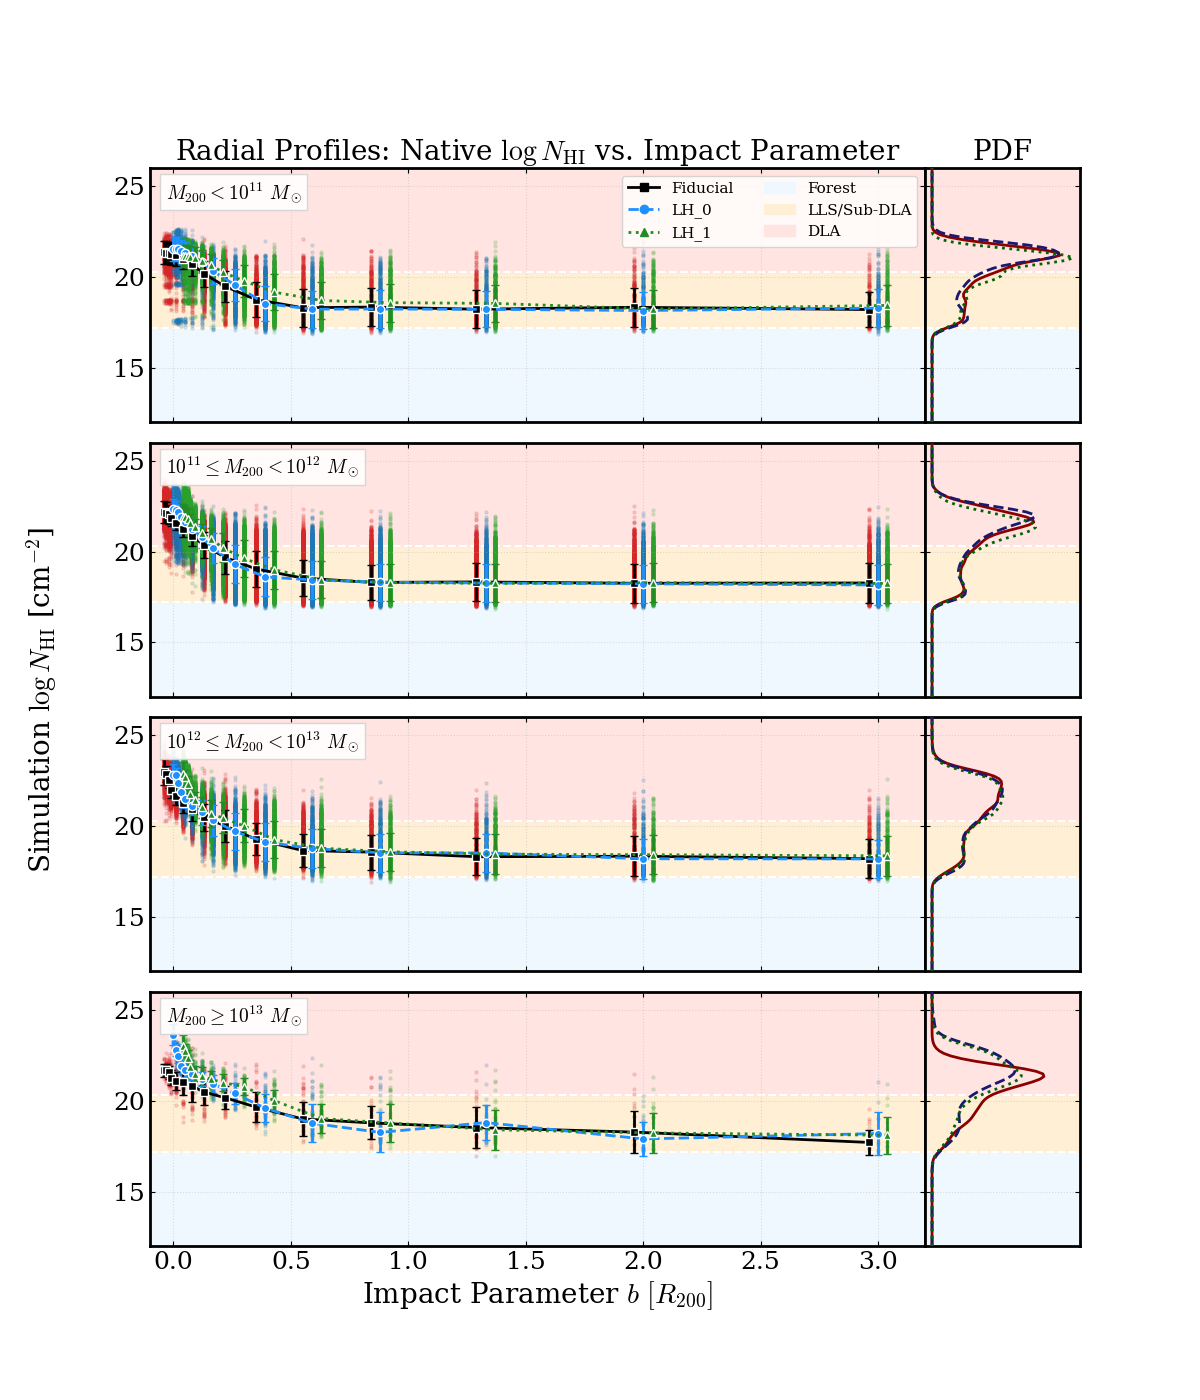

In [5]:
# ==============================================================================
# CELL 4: RADIAL PROFILES - NATIVE COLUMN DENSITY vs IMPACT PARAMETER (BY MASS BINS)
# ==============================================================================
import matplotlib.patches as patches
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

# 1. Define Mass Bins
mass_edges = [0, 1e11, 1e12, 1e13, np.inf]
mass_labels = [
    r'$M_{200} < 10^{11} \ M_\odot$',
    r'$10^{11} \leq M_{200} < 10^{12} \ M_\odot$',
    r'$10^{12} \leq M_{200} < 10^{13} \ M_\odot$',
    r'$M_{200} \geq 10^{13} \ M_\odot$'
]
n_bins = len(mass_labels)

# 2. Figure Setup (Scatter + PDF)
fig_rad, axes_rad = plt.subplots(n_bins, 2, figsize=(12, 3.5 * n_bins), sharex='col', sharey=True,
                                 gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.0, 'hspace': 0.08})
if n_bins == 1: axes_rad = np.array([axes_rad])

# Aesthetics mapping
colors_scat = ['tab:red', 'tab:blue', 'tab:green', 'tab:purple']
colors_med  = ['black', 'dodgerblue', 'forestgreen', 'darkmagenta']
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen', 'indigo']
line_styles = ['-', '--', ':', '-.']
markers     = ['s', 'o', '^', 'D']

c_forest = 'aliceblue'
c_lls    = 'papayawhip'
c_dla    = 'mistyrose'

# Offset width to separate models at the same impact parameter (dodging)
offset_width = 0.04 

for i, (m_low, m_high, m_label) in enumerate(zip(mass_edges[:-1], mass_edges[1:], mass_labels)):
    ax_main, ax_hist = axes_rad[i, 0], axes_rad[i, 1]
    
    # 3. Background Regions
    for ax in [ax_main, ax_hist]:
        ax.axhspan(12.0, 17.2, color=c_forest, zorder=0)
        ax.axhspan(17.2, 20.3, color=c_lls, zorder=0)
        ax.axhspan(20.3, 26.0, color=c_dla, zorder=0)
        ax.axhline(17.2, color='white', ls='--', lw=1.5, zorder=0)
        ax.axhline(20.3, color='white', ls='--', lw=1.5, zorder=0)
        ax.grid(True, ls=':', alpha=0.4)
    
    # Annotate Mass Bin
    ax_main.text(0.02, 0.88, m_label, transform=ax_main.transAxes, fontsize=14, 
                 bbox=dict(facecolor='white', alpha=0.9, edgecolor='lightgray'), zorder=10)

    # 4. Loop through models
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_s = colors_scat[m_idx % len(colors_scat)]
        c_m = colors_med[m_idx % len(colors_med)]
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        mkr = markers[m_idx % len(markers)]
        
        # Calculate X-axis offset for this model to prevent overlap
        x_offset = (m_idx - (n_models - 1) / 2.0) * offset_width
        
        # Filter by mass bin
        df_bin = df_model[(df_model['halo_mass_msun'] >= m_low) & (df_model['halo_mass_msun'] < m_high)]
        
        b_vals, medians, stds = [], [], []
        
        for b_raw in unique_radii:
            df_b = df_bin[df_bin['r_mult_round'] == b_raw]
            
            # STATISTICS ONLY ON DETECTED GAS
            df_valid = df_b[df_b['log_n_hi'] > 1.0] 
            
            if len(df_valid) > 0:
                b_shifted = b_raw + x_offset
                b_vals.append(b_shifted)
                
                # Advisor requested Median +- STD (calculated purely on valid detections)
                med = np.median(df_valid['log_n_hi'])
                std = np.std(df_valid['log_n_hi'])
                medians.append(med)
                stds.append(std)
                
                # Scatter
                ax_main.scatter(np.full(len(df_valid), b_shifted), df_valid['log_n_hi'], 
                                s=5, alpha=0.15, color=c_s, zorder=1)
        
        if len(b_vals) > 0:
            # Plot the connected median +- std
            ax_main.errorbar(b_vals, medians, yerr=stds, fmt=f'{mkr}{ls}', color=c_m, 
                             markersize=6, capsize=3, lw=2.0, mec='white', zorder=5)
            
            # 5. Marginal Distribution (PDF axis)
            df_valid_bin = df_bin[df_bin['log_n_hi'] > 1.0]
            if len(df_valid_bin) > 1:
                kde = gaussian_kde(df_valid_bin['log_n_hi'])
                y_grid = np.linspace(12.0, 26.0, 100)
                ax_hist.plot(kde(y_grid), y_grid, color=c_p, lw=2, ls=ls, zorder=3)

    # 6. Aesthetics
    ax_hist.set_xticks([])
    if i < n_bins - 1:
        ax_main.tick_params(labelbottom=False)

    if i == 0:
        ax_main.set_title(r"Radial Profiles: Native $\log N_{\rm HI}$ vs. Impact Parameter")
        ax_hist.set_title("PDF")
        
        # Build Legend for Models & Regions
        custom_lines = [Line2D([0], [0], color=colors_med[m_idx % len(colors_med)], 
                               lw=2, ls=line_styles[m_idx % len(line_styles)], 
                               marker=markers[m_idx % len(markers)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        region_patches = [patches.Patch(color=c_forest, label='Forest'), 
                          patches.Patch(color=c_lls, label='LLS/Sub-DLA'), 
                          patches.Patch(color=c_dla, label='DLA')]
        
        ax_main.legend(handles=custom_lines + region_patches, loc='upper right', ncol=2, frameon=True, fontsize=11)

# Global Axis Labels
axes_rad[-1, 0].set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
fig_rad.text(0.02, 0.5, r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]", va='center', rotation='vertical', fontsize=20)

axes_rad[-1, 0].set_xlim(-0.1, unique_radii.max() + 0.2)
axes_rad[-1, 0].set_ylim(12.0, 26.0)

plt.show()

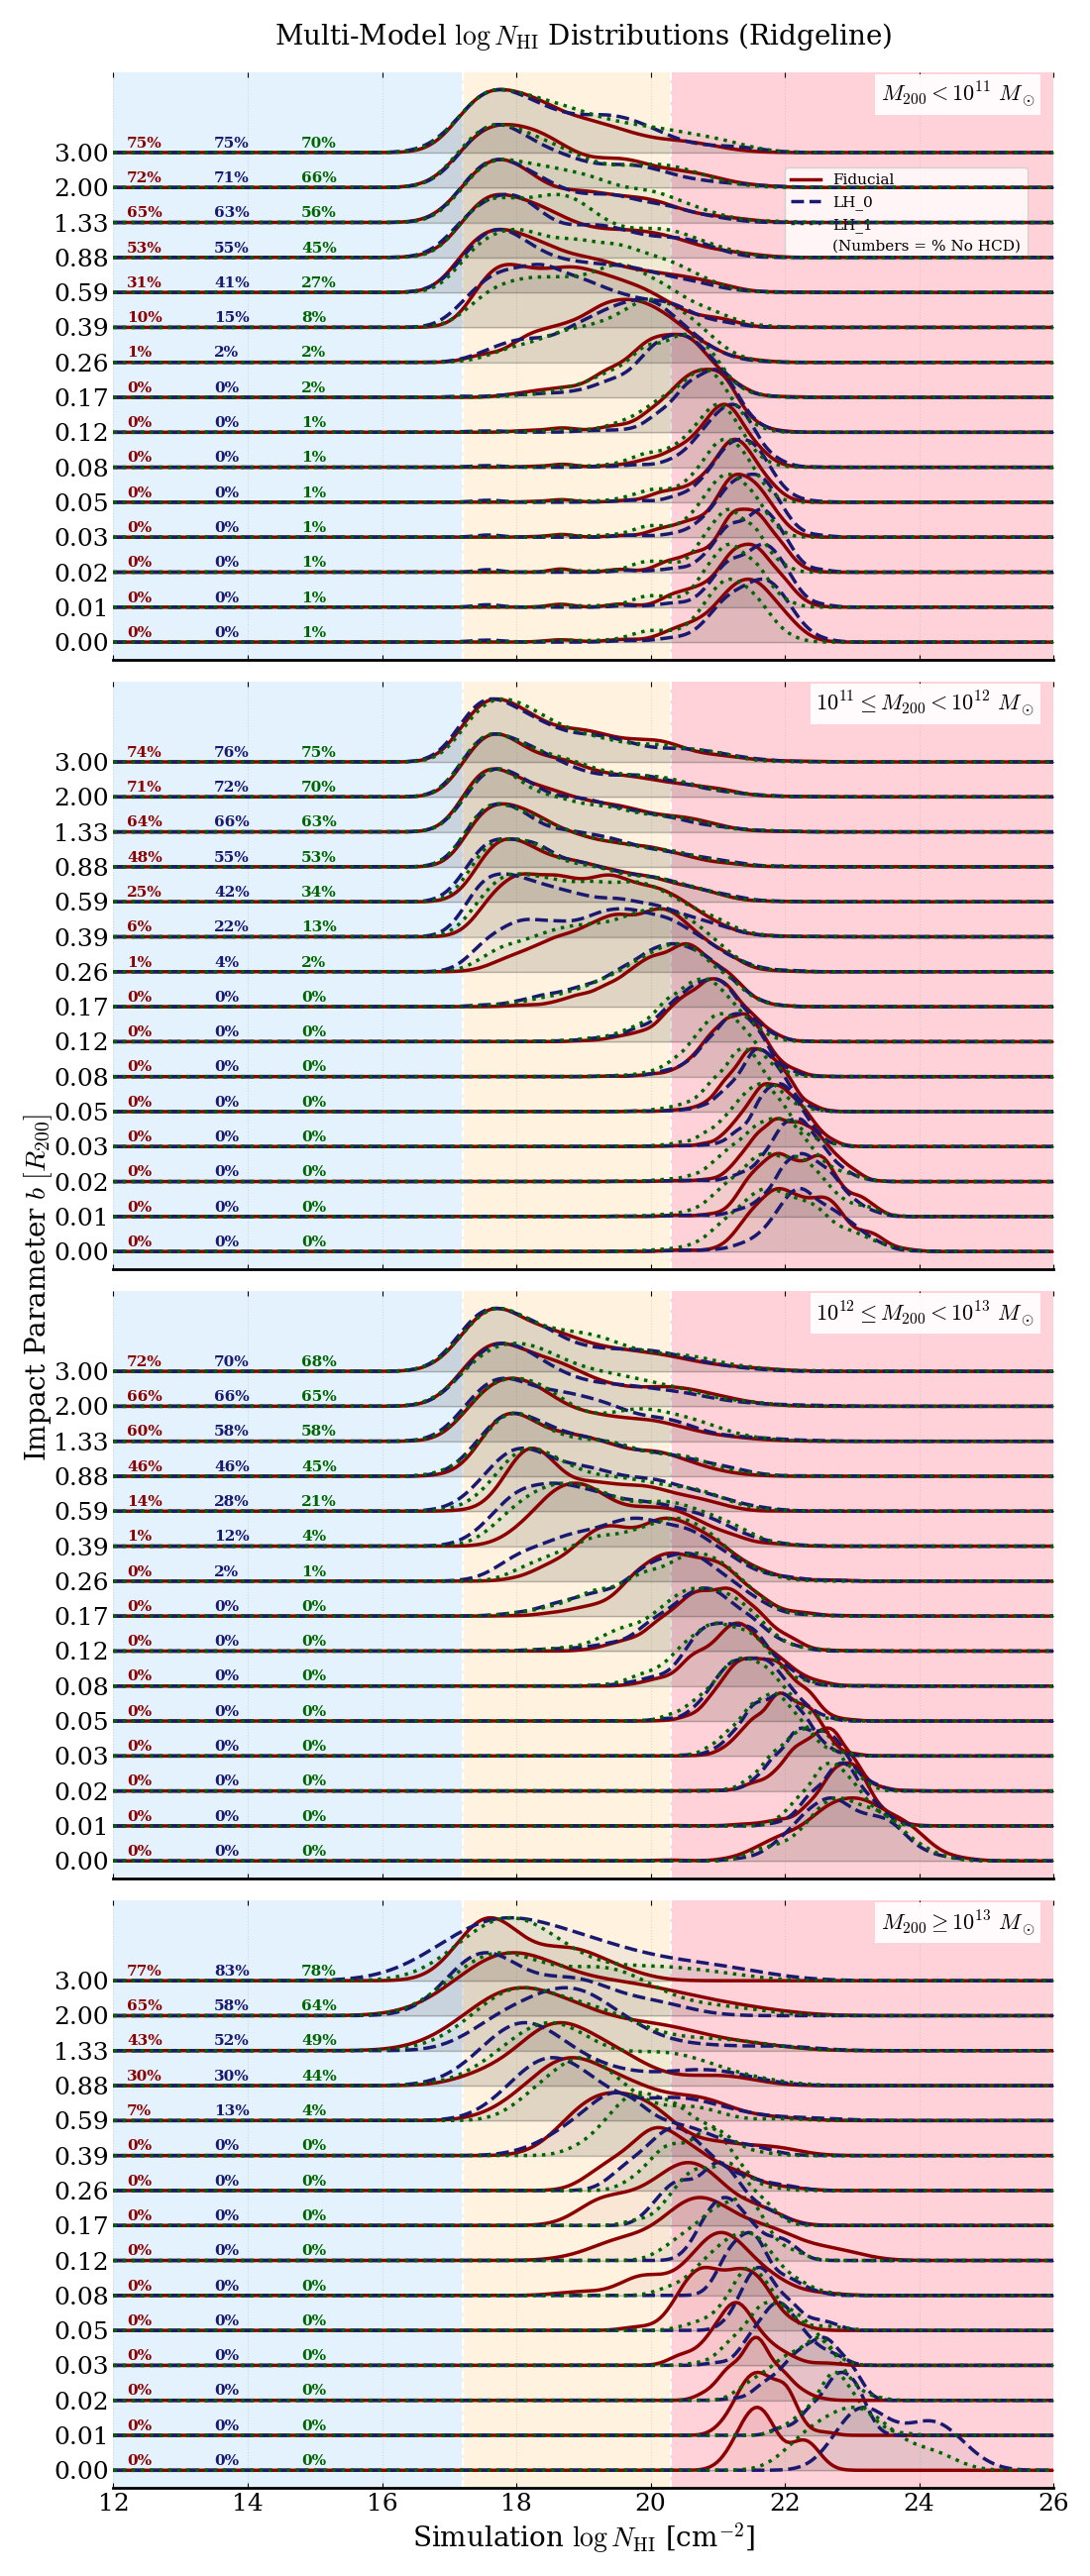

In [7]:
# ==============================================================================
# CELL 5: RADIAL PROFILES - RIDGELINE PLOT (JOYPLOT)
# ==============================================================================
import matplotlib.patches as patches
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

# 1. Define Mass Bins
mass_edges = [0, 1e11, 1e12, 1e13, np.inf]
mass_labels = [
    r'$M_{200} < 10^{11} \ M_\odot$',
    r'$10^{11} \leq M_{200} < 10^{12} \ M_\odot$',
    r'$10^{12} \leq M_{200} < 10^{13} \ M_\odot$',
    r'$M_{200} \geq 10^{13} \ M_\odot$'
]
n_bins = len(mass_labels)

# 2. Figure Setup
# Ridgelines need more vertical space per panel to accommodate the overlapping peaks
fig_ridge, axes_ridge = plt.subplots(n_bins, 1, figsize=(11, 6.5 * n_bins), sharex=True)
if n_bins == 1: axes_ridge = np.array([axes_ridge])

# Aesthetics
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen', 'indigo']
line_styles = ['-', '--', ':', '-.']

c_forest = '#E3F2FD'  
c_lls    = '#FFF3E0'  
c_dla    = '#FFD1D8'  

# Controls how much the peaks overlap the baseline above them
overlap_factor = 1.8  

for i, (m_low, m_high, m_label) in enumerate(zip(mass_edges[:-1], mass_edges[1:], mass_labels)):
    ax = axes_ridge[i]
    
    # 3. Background Regions (Now VERTICAL for the X-axis)
    ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
    ax.axvspan(17.2, 20.3, color=c_lls, zorder=0)
    ax.axvspan(20.3, 26.0, color=c_dla, zorder=0)
    ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
    ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)
    
    ax.grid(axis='x', ls=':', alpha=0.4)
    ax.grid(axis='y', visible=False) 
    
    # Remove top and right spines for a cleaner ridgeline look
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    # Annotate Mass Bin
    ax.text(0.98, 0.95, m_label, transform=ax.transAxes, fontsize=16, ha='right',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'), zorder=30)

    y_ticks = []
    y_labels = []
    
    # 4. Iterate backwards so bottom plots overlap top ones in the foreground
    for i_b in reversed(range(len(unique_radii))):
        b_val = unique_radii[i_b]
        y_base = i_b  # Categorical integer baseline
        
        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        
        # Draw the visual baseline for this impact parameter
        ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
        
        # Base X coordinate for text annotations (inside the Forest region)
        text_x_start = 12.2 
        
        for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
            c_p = colors_pdf[m_idx % len(colors_pdf)]
            ls  = line_styles[m_idx % len(line_styles)]
            
            df_bin = df_model[(df_model['halo_mass_msun'] >= m_low) & (df_model['halo_mass_msun'] < m_high)]
            df_b = df_bin[df_bin['r_mult_round'] == b_val]
            
            tot = len(df_b)
            # KDE computed strictly on valid gas detections
            df_valid = df_b[df_b['log_n_hi'] > 1.0]
            
            if len(df_valid) > 2:
                kde = gaussian_kde(df_valid['log_n_hi'])
                x_grid = np.linspace(12.0, 26.0, 300)
                pdf = kde(x_grid)
                
                if pdf.max() > 0:
                    # Scale PDF heights locally for the ridgeline aesthetic
                    pdf_scaled = (pdf / pdf.max()) * overlap_factor
                    
                    # Draw bold outline and extremely faint transparent fill 
                    ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                    ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
            
            # Percentage of No HCD (<= 17.2, capturing empty skewers naturally via the total count)
            if tot > 0:
                p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                p_nohcd = 0.0
            
            # Annotate percentage color-coded to the model to avoid a messy legend
            ax.text(text_x_start + (m_idx * 1.3), y_base + 0.15, f"{p_nohcd:.0f}%", 
                    color=c_p, fontsize=11, fontweight='bold', zorder=20)

    # Setup categorical Y-axis
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    if i == 0:
        ax.set_title(r"Multi-Model $\log N_{\rm HI}$ Distributions (Ridgeline)", pad=20)
        
        custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                               lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                        for m_idx, model_name in enumerate(dfs_clean.keys())]
        
        custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(Numbers = % No HCD)'))
        
        ax.legend(handles=custom_lines, loc='upper right', ncol=1, frameon=True, fontsize=11, bbox_to_anchor=(0.98, 0.85))

# Global Axis Labels
axes_ridge[-1].set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
fig_ridge.text(0.02, 0.5, r'Impact Parameter $b \ [R_{200}]$', va='center', rotation='vertical', fontsize=20)

axes_ridge[-1].set_xlim(12.0, 26.0)

for ax in axes_ridge:
    ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()

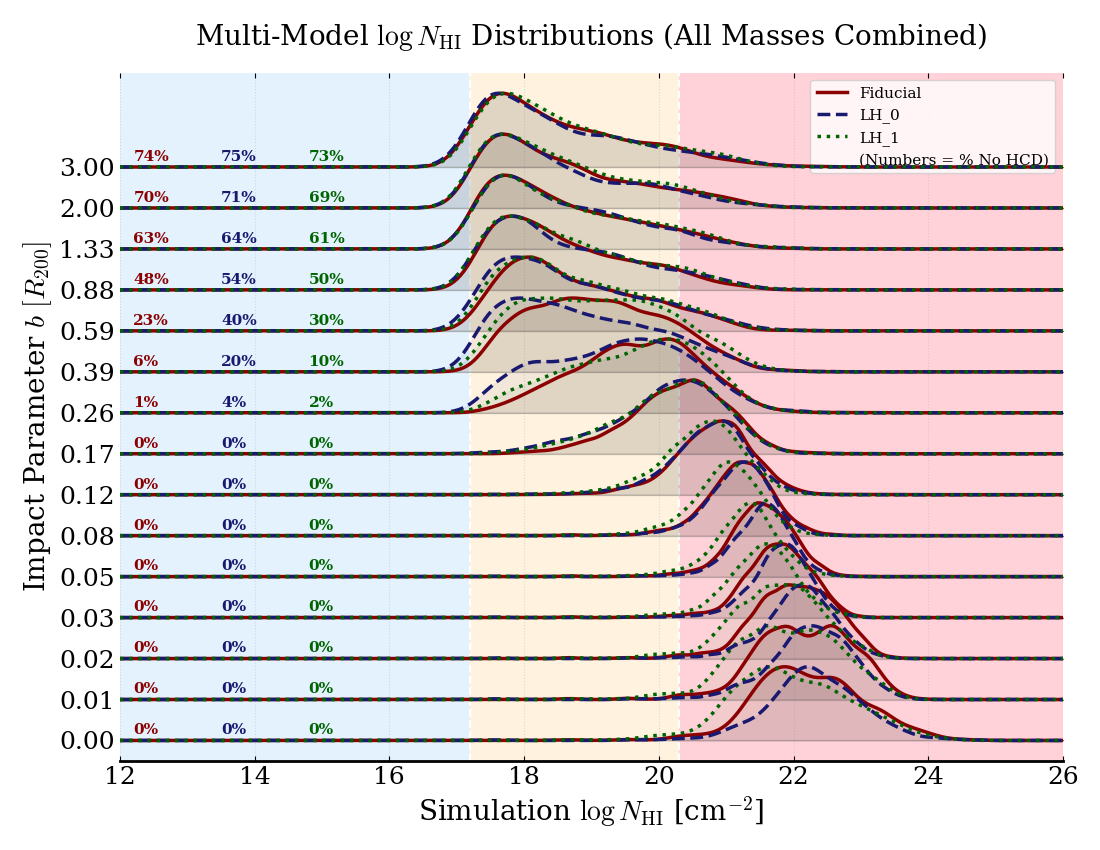

In [8]:
# ==============================================================================
# CELL 5: RADIAL PROFILES - RIDGELINE PLOT (ALL MASSES COMBINED)
# ==============================================================================
import matplotlib.patches as patches
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

# 1. Figure Setup (Single Panel)
fig_ridge, ax = plt.subplots(figsize=(11, 8.5))

# Aesthetics
colors_pdf  = ['darkred', 'midnightblue', 'darkgreen', 'indigo']
line_styles = ['-', '--', ':', '-.']

c_forest = '#E3F2FD'  
c_lls    = '#FFF3E0'  
c_dla    = '#FFD1D8'  

# Controls how much the peaks overlap the baseline above them
overlap_factor = 1.8  

# 2. Background Regions (VERTICAL for the X-axis)
ax.axvspan(12.0, 17.2, color=c_forest, zorder=0)
ax.axvspan(17.2, 20.3, color=c_lls, zorder=0)
ax.axvspan(20.3, 26.0, color=c_dla, zorder=0)
ax.axvline(17.2, color='white', ls='--', lw=1.5, zorder=0)
ax.axvline(20.3, color='white', ls='--', lw=1.5, zorder=0)

ax.grid(axis='x', ls=':', alpha=0.4)
ax.grid(axis='y', visible=False) 

# Remove top and right spines for a cleaner ridgeline look
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

y_ticks = []
y_labels = []

# 3. Iterate backwards so bottom plots overlap top ones in the foreground
for i_b in reversed(range(len(unique_radii))):
    b_val = unique_radii[i_b]
    y_base = i_b  # Categorical integer baseline
    
    y_ticks.append(y_base)
    y_labels.append(f"{b_val:.2f}")
    
    # Draw the visual baseline for this impact parameter
    ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)
    
    # Base X coordinate for text annotations (inside the Forest region)
    text_x_start = 12.2 
    
    for m_idx, (model_name, df_model) in enumerate(dfs_clean.items()):
        c_p = colors_pdf[m_idx % len(colors_pdf)]
        ls  = line_styles[m_idx % len(line_styles)]
        
        # NO MASS FILTERING: Extract directly by impact parameter
        df_b = df_model[df_model['r_mult_round'] == b_val]
        
        tot = len(df_b)
        # KDE computed strictly on valid gas detections
        df_valid = df_b[df_b['log_n_hi'] > 1.0]
        
        if len(df_valid) > 2:
            kde = gaussian_kde(df_valid['log_n_hi'])
            x_grid = np.linspace(12.0, 26.0, 300)
            pdf = kde(x_grid)
            
            if pdf.max() > 0:
                # Scale PDF heights locally for the ridgeline aesthetic
                pdf_scaled = (pdf / pdf.max()) * overlap_factor
                
                # Draw bold outline and extremely faint transparent fill 
                ax.plot(x_grid, y_base + pdf_scaled, color=c_p, lw=2.5, ls=ls, zorder=i_b + 5)
                ax.fill_between(x_grid, y_base, y_base + pdf_scaled, color=c_p, alpha=0.05, zorder=i_b + 4)
        
        # Percentage of No HCD (<= 17.2, capturing empty skewers naturally via the total count)
        if tot > 0:
            p_nohcd = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
        else:
            p_nohcd = 0.0
        
        # Annotate percentage color-coded to the model to avoid a messy legend
        ax.text(text_x_start + (m_idx * 1.3), y_base + 0.15, f"{p_nohcd:.0f}%", 
                color=c_p, fontsize=11, fontweight='bold', zorder=20)

# 4. Setup categorical Y-axis
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)

ax.set_title(r"Multi-Model $\log N_{\rm HI}$ Distributions (All Masses Combined)", pad=20)

# Build Legend
custom_lines = [Line2D([0], [0], color=colors_pdf[m_idx % len(colors_pdf)], 
                       lw=2.5, ls=line_styles[m_idx % len(line_styles)], label=model_name) 
                for m_idx, model_name in enumerate(dfs_clean.keys())]

custom_lines.append(Line2D([0], [0], marker='none', linestyle='none', label='(Numbers = % No HCD)'))

ax.legend(handles=custom_lines, loc='upper right', ncol=1, frameon=True, fontsize=11)

# Global Axis Labels
ax.set_xlabel(r"Simulation $\log N_{\rm HI}$ [cm$^{-2}$]")
ax.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')

ax.set_xlim(12.0, 26.0)
ax.set_ylim(-0.5, len(unique_radii) + overlap_factor - 0.5)

plt.tight_layout()
plt.show()